# Is the problem in the model or in the data?

Before you explain a model, look at its data. This notebook looks at the real COMPAS data
that ProPublica published: 7 214 defendants from Broward County, Florida, who were screened
with the COMPAS tool in 2013 and 2014. Many papers on fairness and explainability use this
data set as a benchmark. It has a processing error
([Barenstein 2019](https://arxiv.org/abs/1906.04711)).

This notebook needs the network to download the data.

In [1]:
import warnings
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from recidivism_data.theme import BLUE, INK2, ORANGE, use_theme
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
use_theme()

URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
CUTOFF = pd.Timestamp("2014-04-01")  # two years before the end of the data collection

try:
    raw = pd.read_csv(StringIO(requests.get(URL, timeout=30).text))
    raw["screened"] = pd.to_datetime(raw["compas_screening_date"])
    print(f"{len(raw)} defendants; rearrested within two years: {raw['two_year_recid'].mean():.1%}")
except requests.RequestException as error:
    raw = None
    print(f"no download possible ({type(error).__name__}); the other cells do nothing")

7214 defendants; rearrested within two years: 45.1%


## Look at the data

The people by the quarter of their screening and by the outcome.

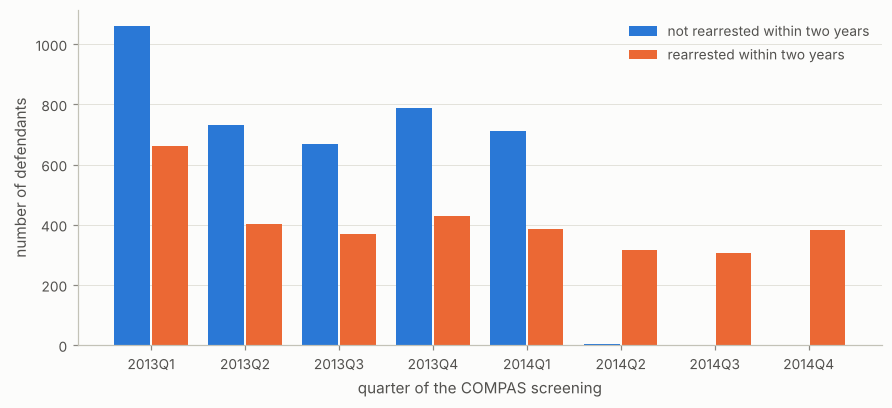

,not rearrested,rearrested,share rearrested
quarter of the screening,,,
2013Q1,1060,662,38%
2013Q2,733,401,35%
2013Q3,669,368,35%
2013Q4,788,430,35%
2014Q1,710,386,35%
2014Q2,3,315,99%
2014Q3,0,305,100%
2014Q4,0,384,100%


In [2]:
def by_quarter(raw: pd.DataFrame) -> pd.DataFrame:
    quarter = raw["screened"].dt.to_period("Q").astype(str)
    outcome = raw["two_year_recid"].map({0: "not rearrested", 1: "rearrested"})
    table = pd.crosstab(quarter, outcome)
    table.index.name, table.columns.name = "quarter of the screening", None

    _, ax = plt.subplots(figsize=(8, 3.6))
    x = np.arange(len(table))
    ax.bar(
        x - 0.2,
        table["not rearrested"],
        width=0.38,
        color=BLUE,
        label="not rearrested within two years",
    )
    ax.bar(
        x + 0.2, table["rearrested"], width=0.38, color=ORANGE, label="rearrested within two years"
    )
    ax.set_xticks(x, table.index)
    ax.set(xlabel="quarter of the COMPAS screening", ylabel="number of defendants")
    ax.grid(axis="x", visible=False)
    ax.legend(labelcolor=INK2)
    plt.show()
    return table.assign(
        **{"share rearrested": (table["rearrested"] / table.sum(axis=1)).map("{:.0%}".format)}
    )


by_quarter(raw) if raw is not None else None

From the second quarter of 2014, almost all people in the data were rearrested. That is not a
fact about crime in Florida.

**The cause.** "Not rearrested within two years" is only known for a person who was observed
for two years. Thus people who were screened after 1 April 2014 were removed from the data.
But this filter was applied only to the people without a rearrest. The people with a
rearrest were kept to the end of 2014.

## The same filter for both groups

In [3]:
if raw is not None:
    late = raw["screened"] > CUTOFF
    y = raw["two_year_recid"]
    print(
        f"screened after {CUTOFF.date()}: {int((late & (y == 1)).sum())} rearrested, {int((late & (y == 0)).sum())} not rearrested"
    )
    kept = raw[~late]
    print(f"{len(kept)} defendants remain ({int(late.sum())} removed)")
    print(
        f"rearrested within two years: {kept['two_year_recid'].mean():.1%}  (published data: {y.mean():.1%})"
    )

screened after 2014-04-01: 998 rearrested, 0 not rearrested
6216 defendants remain (998 removed)
rearrested within two years: 36.2%  (published data: 45.1%)


The rate of rearrest in the data set is about 9 percentage points too high. Each model that
is trained on the published data, and each result about such a model, has this error in it.

## A model can find such an error

If you let a model see the day of the screening and then ask the model what it uses, the
explanation points to the problem.

In [4]:
if raw is not None:
    X = pd.DataFrame(
        {
            "age": raw["age"],
            "priors": raw["priors_count"],
            "male": (raw["sex"] == "Male").astype(int),
            "screening day": (raw["screened"] - raw["screened"].min()).dt.days,
        }
    )
    for label, columns in [
        ("age, priors, sex", ["age", "priors", "male"]),
        ("... and the screening day", list(X.columns)),
    ]:
        X_fit, X_val, y_fit, y_val = train_test_split(X[columns], y, test_size=0.2, random_state=42)
        model = HistGradientBoostingClassifier(
            max_iter=100, max_depth=3, learning_rate=0.05, random_state=0
        )
        model.fit(X_fit, y_fit)
        print(f"features {label}: accuracy {model.score(X_val, y_val):.3f}")
    importance = permutation_importance(model, X_val, y_val, n_repeats=20, random_state=0)
    for name, value in sorted(zip(columns, importance.importances_mean), key=lambda item: -item[1]):
        print(f"   permutation importance of {name:<14}{value:.3f}")
    after = X_val["screening day"] > (CUTOFF - raw["screened"].min()).days
    print(
        f"predicted risk of the validation people screened after the cutoff: {model.predict_proba(X_val[after])[:, 1].mean():.2f} on average"
    )

features age, priors, sex: accuracy 0.691
features ... and the screening day: accuracy 0.757


   permutation importance of priors        0.110
   permutation importance of screening day 0.101
   permutation importance of age           0.048
   permutation importance of male          -0.001
predicted risk of the validation people screened after the cutoff: 1.00 on average


The model is "more accurate" with the screening day, and the day is almost as important as the
number of priors. But the day of a screening cannot cause a rearrest. A high importance of
such a feature is a sign of a problem in the data, not a finding about people.

The other notebooks in this repository that use the COMPAS data (in projects 01 and 03) use
the data as published, as most papers do.